# The Data and the Graph

> **About this notebook, version 1.0.0 (17 November 2026).** The second of five notebooks of *Polymer Neural Nets*. It uses the theory of notebook 00 (equation numbers such as (6.3) refer to it) and the data files in `data/`, the trained models in `models/` and the source code in `src/polymer_nn`. Python 3.14 with NumPy, SymPy, Matplotlib, PyTorch, PyTorch Geometric and OpenMM.

*Where every number the networks learn from comes from, how it is stored, how one configuration becomes a graph, what goes into the network, what happens inside it, and what comes out, drawn in full with its symbols*

**Dara O Shayda**  
Republic of Ireland  
*dara@compclassnotes.com*  

**Noor Hoshino**  
<img alt="نور 星野" src="figures/noor-name.png" height="22">  
Advanced AI System Programming  
Hokkaido Prefecture, Japan  
*noor@compclassnotes.com*  
Computational Classnotes · revision 1  

<p align='left' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>

## Abstract

A network can only be as good as its data, and it can only be understood if one knows exactly what it receives and what it returns. This notebook answers five questions with the actual files of the repository. *Where do the data come from?* From our own simulations: every configuration, force and energy was computed by OpenMM from the Kremer–Grest model, with the commands, seeds and settings listed in section 1; nothing was downloaded, and nothing is measured. *How are the data organised?* Section 2 opens every file and lists each array with its shape, type, unit and meaning. It checks that the stored forces are the exact forces of the model and that successive frames are nearly independent. *How does a configuration become network input?* Section 3 builds the graph of a real 32-bead frame and draws it completely, with its adjacency matrix. Section 4 lists the tensors that PyTorch Geometric hands to the network, for one chain and for a batch of chains. *What happens inside?* Section 5 draws the full computational graph of the network with the symbol of every quantity and the shape of every tensor. Section 6 writes the network symbolically on a three-bead chain with SymPy, derives the forces in closed form, and proves and checks that an invariant network gives forces that are sums of pair forces along the edges of the graph. *What comes out?* Section 7 runs the trained network on a frame it has never seen. It shows the energy, the energy of every bead and the force on every bead, next to the exact values from OpenMM.

**Keywords:** training data; molecular dynamics; OpenMM; Kremer–Grest; NumPy archive; frame; graph; edge index; adjacency matrix; batch; message passing; computational graph; radial basis; automatic differentiation; SymPy; central forces; Newton's third law; energy per bead; force field

## Index

- Section 1, where the data come from: Figure 1, Table 1, cell c.1.
- Section 2, how the data are organised: Tables 2–5, Figure 2, cells c.2–c.4.
- Section 3, from a frame to a graph: Eq. (1), Figures 3–4, Table 6, cell c.5.
- Section 4, the input tensors: Tables 7–8, cell c.6.
- Section 5, inside the network: Figure 5, Tables 9–10, cells c.7–c.8.
- Section 6, symbolics on the graph: Eqs. (2)–(6), Theorem 1, Figure 6, Table 11, cells c.9–c.10.
- Section 7, what comes out: Figures 7–8, Table 12, cell c.11.
- Section 8, summary: Table 13.

## 0. Settings

Cell c.0 makes the notebook run in any Jupyter: it installs missing libraries, finds the repository folder or downloads it once from GitHub into `~/polymer-neural-nets` when this notebook is opened on its own, and sets the style of figures and tables.

In [1]:
# c.0
# Setup. This cell makes the notebook run in any Jupyter, three ways:
#  (1) inside the repository folder (e.g. `uv run jupyter lab`, or `pip install -r requirements.txt` then `jupyter lab`);
#  (2) in any Python environment: libraries that are missing are installed with pip into this kernel;
#  (3) as a single notebook file on its own: the code and data of the repository are downloaded once from
#      GitHub into the folder polymer-neural-nets in your home folder.
import importlib.util, subprocess, sys, io, zipfile, urllib.request, warnings
from pathlib import Path
warnings.filterwarnings("ignore")   # library notices (tqdm, TorchScript) are not part of the results
NEED = {"numpy": "numpy", "scipy": "scipy", "sympy": "sympy", "matplotlib": "matplotlib", "torch": "torch",
        "torch_geometric": "torch-geometric", "openmm": "openmm", "IPython": "ipython"}
missing = [pkg for mod, pkg in NEED.items() if importlib.util.find_spec(mod) is None]
if sys.platform == "emscripten":                                 # JupyterLite / Pyodide: Python inside the web page
    raise SystemExit("\n".join([
        "This Jupyter runs Python inside the web browser (JupyterLite / Pyodide, WebAssembly).",
        "PyTorch and OpenMM are not available there, and nothing can be installed with pip, so this notebook",
        "cannot run in it. The saved results are still shown in the notebook, and in the .md and .pdf editions.",
        "",
        "To run it, use Jupyter with a real Python on your computer. It also opens in the browser. In a terminal:",
        "  1. install uv (once):   curl -LsSf https://astral.sh/uv/install.sh | sh",
        "                          (Windows PowerShell: irm https://astral.sh/uv/install.ps1 | iex)",
        "  2. get the repository:  git clone https://github.com/lossofgenerality/polymer-neural-nets",
        "                          cd polymer-neural-nets",
        "  3. install and start:   uv sync   then   uv run jupyter notebook",
        "Then open this notebook in the Jupyter tab that appears and choose Kernel → Restart Kernel and Run All Cells."]))
def install(pkgs):
    """Install pkgs into the Python of this kernel; try pip, then uv; explain clearly if neither works."""
    import shutil
    tries = [[sys.executable, "-m", "pip", "install", *pkgs]]
    if shutil.which("uv"):
        tries.append(["uv", "pip", "install", "--python", sys.executable, *pkgs])
    errors = []
    for cmd in tries:
        try:
            r = subprocess.run(cmd, capture_output=True, text=True)
            if r.returncode == 0:
                importlib.invalidate_caches(); return
            errors.append(f"{' '.join(cmd[:4])} …: exit code {r.returncode}\n{(r.stderr or r.stdout)[-1200:]}")
        except OSError as e:
            errors.append(f"{' '.join(cmd[:4])} …: could not be started ({e})")
    managed = any("externally-managed" in e for e in errors)
    raise SystemExit("\n".join([
        "Could not install " + ", ".join(pkgs) + " into the Python of this Jupyter kernel:", "    " + sys.executable, "",
        *errors, "",
        "Fix it in a terminal, in the folder of this repository, with one of these, then restart the kernel:",
        "  (a) uv:   uv sync   and then   uv run jupyter notebook      (uses the exact versions of uv.lock)",
        "  (b) venv: python3 -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt && jupyter notebook",
        "            (Windows: .venv\\Scripts\\activate)",
        f"  (c) this kernel's Python: \"{sys.executable}\" -m pip install " + " ".join(pkgs),
        "This Python is managed by the system or Homebrew and refuses installs: use (a) or (b)." if managed else ""]))
if missing:
    print("installing", ", ".join(missing), "(first run only; torch is large) ...")
    install(missing)
def find_repo():
    for q in [Path.cwd(), *Path.cwd().parents]:                  # (1) this notebook is inside the repository
        if (q / "src" / "polymer_nn").is_dir() and (q / "data").is_dir():
            return q
    home = Path.home() / "polymer-neural-nets"                    # (3) download it once
    if not (home / "src" / "polymer_nn").is_dir():
        url = "https://github.com/lossofgenerality/polymer-neural-nets/archive/refs/heads/main.zip"
        print("downloading the repository (code, data, models) from", url)
        with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
            top = z.namelist()[0].split("/")[0]
            for m in z.infolist():
                rel = m.filename[len(top) + 1:]
                if rel and not m.is_dir():
                    (home / rel).parent.mkdir(parents=True, exist_ok=True)
                    (home / rel).write_bytes(z.read(m))
    return home
ROOT = find_repo()
sys.path.insert(0, str(ROOT / "src"))                             # use the repository's polymer_nn
import json, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from polymer_nn import nbtools as nb
from polymer_nn.nbtools import table, nform, sci, savefig, figFont, wFull, wHalf, red, blue, green, orange, grey
nb.setup(threads=2)                 # plot style and 2 CPU threads; figures are saved in ./figures
DATA = ROOT / "data"                # the reference data made by scripts/generate_data.py
torch.manual_seed(0); rng = np.random.default_rng(0)
print("repository folder:", ROOT.name, "| Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__)

repository folder: polymer-neural-nets | Python 3.14.6 | torch 2.15.0+cu132 | numpy 2.5.5


## 1. Where the data come from

**All the data are made by this repository.** There is no external dataset and there are no experimental measurements. The networks learn to imitate a *physical model*, the Kremer–Grest bead-spring chain (notebook 00, Eqs. (10.6)–(10.7)): FENE springs between neighbours along the chain and a WCA repulsion between every pair of beads. For a model, the "true" force on every bead can be computed exactly, so the learned forces can be checked exactly.

The open-source molecular-dynamics engine OpenMM [eastman2017] does the computing. The script `scripts/generate_data.py` calls `polymer_nn.sim`, which

1. builds an OpenMM `System`: N particles of unit mass, a `CustomBondForce` with the FENE formula for the N − 1 bonds, and a `CustomNonbondedForce` with the WCA formula for all pairs (cutoff $2^{1/6}$ σ, no periodic box: a single chain in implicit good solvent);
2. places the beads on a random self-avoiding walk with steps of 0.97 σ and removes overlaps with an energy minimisation;
3. runs Langevin dynamics (`LangevinMiddleIntegrator`, notebook 00, Eq. (9.3)) at k_BT = 1 ε. After an equilibration that is thrown away, it records a *frame* every `stride` steps: the positions of all beads, the exact force on every bead, and the potential energy.

Because the thermostat samples the Boltzmann distribution p(x) ∝ exp(−E(x)/k_BT), the frames are typical configurations of the chain at this temperature. They are exactly the configurations a learned force field will meet in a simulation. Figure 1 shows the whole pipeline, and Table 1 lists every data file with the command that made it.

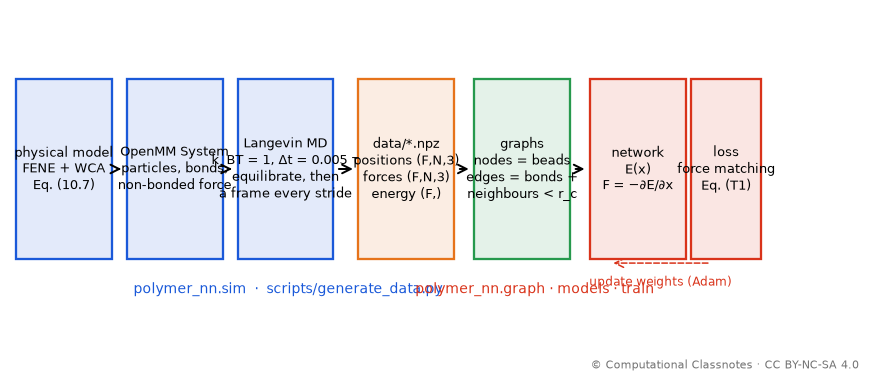

file,made by (all with scripts/generate_data.py),what it holds
data/kg_N32.npz,--model kg --n-beads 32 --frames 2000 --stride 100 --equilibrate 20000 --seed 0,"training data: 2000 frames of one 32-bead chain, friction 1/τ, frames 0.5 τ apart"
data/kg_N64.npz,--model kg --n-beads 64 --frames 300 --stride 100 --seed 7,test data: a chain length never used in training
data/scaling_kg.npz,--scaling --models kg --replicas 8 --frames 200 --stride 1000 --equilibrate 100000,"R_g of N = 16, 32, 64, 128: 8 independent chains each, friction 0.1/τ, pivot-MC pre-relaxed, plus a pivot-MC check"
data/scaling_ideal.npz,--scaling --models ideal --replicas 16 --frames 1000 --stride 1000 --equilibrate 100000,"the same for the ideal chain (control case, ν = 1/2)"


In [2]:
# c.1
# Figure 1: the pipeline from physical model to trained network; Table 1: every data file and how it was made
fig, ax = plt.subplots(figsize=(wFull * 1.45, wHalf * 1.25)); ax.axis("off"); ax.set_xlim(0, 15); ax.set_ylim(0, 4.2)
boxes = [(0.1, "physical model\nFENE + WCA\nEq. (10.7)", blue), (2.3, "OpenMM System\nparticles, bonds,\nnon-bonded force", blue),
         (4.5, "Langevin MD\nk_BT = 1, Δt = 0.005 τ\nequilibrate, then\na frame every stride", blue),
         (6.9, "data/*.npz\npositions (F,N,3)\nforces (F,N,3)\nenergy (F,)", orange),
         (9.2, "graphs\nnodes = beads\nedges = bonds +\nneighbours < r_c", green), (11.5, "network\nE(x)\nF = −∂E/∂x", red),
         (13.5, "loss\nforce matching\nEq. (T1)", red)]
for x0, txt, c in boxes:
    ax.add_patch(plt.Rectangle((x0, 0.9), 1.9 if x0 < 13 else 1.4, 2.4, fc=(*c, 0.12), ec=c, lw=1.5))
    ax.text(x0 + (0.95 if x0 < 13 else 0.7), 2.1, txt, ha="center", va="center", fontsize=8.5)
for a, b in zip([b[0] for b in boxes][:-1], [b[0] for b in boxes][1:]):
    ax.annotate("", xy=(b - 0.05, 2.1), xytext=(a + 1.95, 2.1), arrowprops=dict(arrowstyle="->", lw=1.3))
ax.text(5.5, 0.45, "polymer_nn.sim  ·  scripts/generate_data.py", ha="center", fontsize=9, color=blue)
ax.text(10.4, 0.45, "polymer_nn.graph · models · train", ha="center", fontsize=9, color=red)
ax.annotate("", xy=(11.9, 0.85), xytext=(13.9, 0.85), arrowprops=dict(arrowstyle="->", color=red, ls="--"))
ax.text(12.9, 0.55, "update weights (Adam)", ha="center", fontsize=8, color=red)
savefig(fig, "fig1_pipeline"); plt.show()
table([["file", "made by (all with scripts/generate_data.py)", "what it holds"],
       ["data/kg_N32.npz", "--model kg --n-beads 32 --frames 2000 --stride 100 --equilibrate 20000 --seed 0",
        "training data: 2000 frames of one 32-bead chain, friction 1/τ, frames 0.5 τ apart"],
       ["data/kg_N64.npz", "--model kg --n-beads 64 --frames 300 --stride 100 --seed 7",
        "test data: a chain length never used in training"],
       ["data/scaling_kg.npz", "--scaling --models kg --replicas 8 --frames 200 --stride 1000 --equilibrate 100000",
        "R_g of N = 16, 32, 64, 128: 8 independent chains each, friction 0.1/τ, pivot-MC pre-relaxed, plus a pivot-MC check"],
       ["data/scaling_ideal.npz", "--scaling --models ideal --replicas 16 --frames 1000 --stride 1000 --equilibrate 100000",
        "the same for the ideal chain (control case, ν = 1/2)"]], "Table 1. The data files and the commands that made them")

*Figure 1. From the physical model to a trained network. Blue: the simulation that makes the data (section 1). Orange: the stored data (section 2). Green: the graph built from each frame (sections 3–4). Red: the network and its training (sections 5–7 and notebook 03).*

The simulations take a few minutes on one CPU core: 2000 frames × 100 steps = 200 000 steps for the training set. The time step Δt = 0.005 τ is small enough for the stiff FENE springs; frames are 100 steps = 0.5 τ apart.

## 2. How the data are organised

Every data file is a NumPy archive (`.npz`): a zip of named arrays, opened with `np.load`. The single-chain files all have the same layout, written by `polymer_nn.sim.sample`. Cell c.2 opens them and lists every array (Table 2), and prints the first numbers of the first frame (Table 3).

In [3]:
# c.2
# open the data files and list every array: name, shape, type, unit and meaning
meaning = {"positions": ("σ", "x_i: position of bead i in frame f; axes (frame f, bead i, x/y/z)"),
           "forces": ("ε/σ", "F_i = −∂E/∂x_i: exact OpenMM force on bead i, same axes"),
           "energy": ("ε", "E(x): total potential energy of frame f, Eq. (10.7)"),
           "n_beads": ("–", "N, the number of beads"), "model": ("–", "'kg' = Kremer–Grest"), "kT": ("ε", "k_BT")}
rows = [["file", "array", "shape", "type", "unit", "meaning"]]
for fname in ("kg_N32.npz", "kg_N64.npz"):
    d = np.load(DATA / fname)
    for k in d.files:
        u, mtxt = meaning[k]; a = d[k]
        rows.append([fname, k, str(a.shape) if a.shape else "scalar", str(a.dtype), u, mtxt])
table(rows, "Table 2. The single-chain data files")
d32 = np.load(DATA / "kg_N32.npz"); P, F, E = d32["positions"], d32["forces"], d32["energy"]
table([["bead i", "x_i (σ)", "F_i (ε/σ)"]] +
      [[i, "(" + ", ".join(f"{v:+.3f}" for v in P[0, i]) + ")", "(" + ", ".join(f"{v:+.2f}" for v in F[0, i]) + ")"] for i in range(5)] +
      [["…", "…", "…"], ["energy of frame 0", f"E = {E[0]:.3f} ε", f"= {E[0] / 32:.3f} ε per bead"]],
      "Table 3. The first numbers of frame 0 of data/kg_N32.npz")

file,array,shape,type,unit,meaning
kg_N32.npz,positions,"(2000, 32, 3)",float32,σ,"x_i: position of bead i in frame f; axes (frame f, bead i, x/y/z)"
kg_N32.npz,forces,"(2000, 32, 3)",float32,ε/σ,"F_i = −∂E/∂x_i: exact OpenMM force on bead i, same axes"
kg_N32.npz,energy,"(2000,)",float64,ε,"E(x): total potential energy of frame f, Eq. (10.7)"
kg_N32.npz,n_beads,scalar,int64,–,"N, the number of beads"
kg_N32.npz,model,scalar,<U2,–,'kg' = Kremer–Grest
kg_N32.npz,kT,scalar,float64,ε,k_BT
kg_N64.npz,positions,"(300, 64, 3)",float32,σ,"x_i: position of bead i in frame f; axes (frame f, bead i, x/y/z)"
kg_N64.npz,forces,"(300, 64, 3)",float32,ε/σ,"F_i = −∂E/∂x_i: exact OpenMM force on bead i, same axes"
kg_N64.npz,energy,"(300,)",float64,ε,"E(x): total potential energy of frame f, Eq. (10.7)"
kg_N64.npz,n_beads,scalar,int64,–,"N, the number of beads"


bead i,x_i (σ),F_i (ε/σ)
0,"(+2.947, -8.379, -1.387)","(+2.92, -1.15, +2.68)"
1,"(+3.630, -8.649, -0.760)","(+32.88, +0.12, -6.57)"
2,"(+4.634, -8.678, -0.869)","(-37.32, +5.83, +27.35)"
3,"(+4.571, -8.480, +0.099)","(+0.76, +19.23, -14.61)"
4,"(+4.542, -7.549, +0.442)","(+19.06, -108.49, +13.26)"
…,…,…
energy of frame 0,E = 642.068 ε,= 20.065 ε per bead


Two facts about the data matter for training. First, the stored forces must be the exact forces of the model, so that the network learns the model and not some numerical error. Second, the frames should be nearly independent, so that 2000 frames carry close to 2000 frames' worth of information. Cell c.3 recomputes the energy and forces of 20 frames with OpenMM's double-precision `Reference` platform. It also measures the correlation between successive frames of the radius of gyration (R_g), the slowest quantity of the chain.

In [4]:
# c.3
# the stored forces are exact, and successive frames are nearly independent
from polymer_nn.sim import reference_energy_forces
from polymer_nn.analysis import radius_of_gyration, bond_lengths
errF, errE = [], []
for k in range(0, 2000, 100):
    e, f = reference_energy_forces(P[k].astype(float))
    errF.append(np.abs(f - F[k]).max()); errE.append(abs(e - E[k]))
rg = radius_of_gyration(P)
def acf(a, lag): a = a - a.mean(); return float((a[:-lag] * a[lag:]).mean() / (a * a).mean())
table([["check", "value"], ["max |stored F − recomputed F| (ε/σ), 20 frames", sci(max(errF))],
       ["  for comparison: RMS force", f"{np.sqrt((F**2).mean()):.2f} ε/σ"],
       ["max |stored E − recomputed E| (ε)", sci(max(errE))],
       ["correlation of R_g between successive frames (lag 1)", f"{acf(rg, 1):.3f}"],
       ["correlation at lag 5 and 20", f"{acf(rg, 5):.3f}, {acf(rg, 20):.3f}"],
       ["mean bond length (σ)", f"{bond_lengths(P).mean():.4f}"]], "Table 4. The data are exact and nearly independent")

check,value
"max |stored F − recomputed F| (ε/σ), 20 frames",3 × 10⁻⁴
for comparison: RMS force,25.33 ε/σ
max |stored E − recomputed E| (ε),1.2 × 10⁻⁴
correlation of R_g between successive frames (lag 1),0.989
correlation at lag 5 and 20,"0.864, 0.457"
mean bond length (σ),0.9710


The force differences are at the level of float32 rounding: the positions and forces are stored in single precision, which has about 7 significant digits. That is plenty for training, which itself runs in float32. The correlation of R_g between successive frames shows how quickly the chain forgets its shape. A small number means each frame is a nearly new sample.

The two scaling files hold the results of many independent chains per length, used for the R_g ∼ N^ν check (notebooks 02 and 04). The trained models and the results of the checks are stored in the same spirit. Cell c.4 lists them (Table 5) and draws three frames of the training data (Figure 2).

file,key,shape,meaning
data/scaling_kg.npz,sizes,"(4,)",chain lengths N
data/scaling_kg.npz,kg_final_N16,"(8, 16, 3)","last configuration of each replica (replica, bead, xyz)"
data/scaling_kg.npz,kg_pivot_rg,"(4,)",⟨R_g²⟩^½ from pivot Monte Carlo started at the final MD frames (σ)
data/scaling_kg.npz,kg_final_N32,"(8, 32, 3)","last configuration of each replica (replica, bead, xyz)"
data/scaling_kg.npz,kg_final_N64,"(8, 64, 3)","last configuration of each replica (replica, bead, xyz)"
data/scaling_kg.npz,kg_final_N128,"(8, 128, 3)","last configuration of each replica (replica, bead, xyz)"
data/scaling_kg.npz,kg_rg,"(4,)",⟨R_g²⟩^½ from MD at each N (σ)
data/scaling_kg.npz,kg_rg_sem,"(4,)",its standard error from the spread of the replicas
models/invariant.pt,name,–,which network ('invariant' or 'egnn')
models/invariant.pt,config,–,"constructor arguments {'hidden': 64, 'layers': 3, 'cutoff': 1.5}"


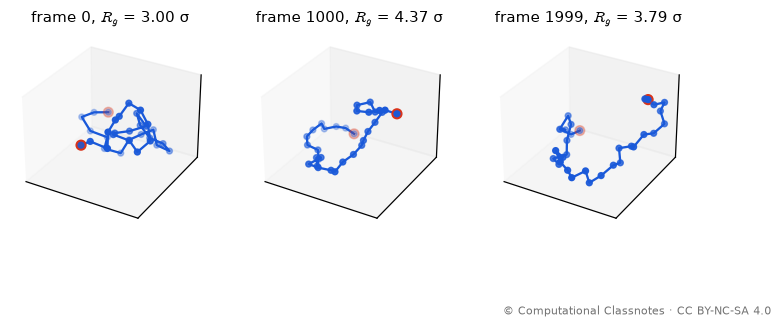

In [5]:
# c.4
# the other files: scaling data, trained models, check results
rows = [["file", "key", "shape", "meaning"]]
s_kg = np.load(DATA / "scaling_kg.npz")
desc = {"sizes": "chain lengths N", "kg_rg": "⟨R_g²⟩^½ from MD at each N (σ)", "kg_rg_sem": "its standard error from the spread of the replicas",
        "kg_pivot_rg": "⟨R_g²⟩^½ from pivot Monte Carlo started at the final MD frames (σ)"}
for k in s_kg.files:
    rows.append(["data/scaling_kg.npz", k, str(s_kg[k].shape), desc.get(k, "last configuration of each replica (replica, bead, xyz)")])
ck = torch.load(ROOT / "models/invariant.pt", weights_only=False)
rows += [["models/invariant.pt", k, "–", {"name": "which network ('invariant' or 'egnn')", "config": f"constructor arguments {ck['config']}",
          "state_dict": f"{len(ck['state_dict'])} weight tensors, {sum(v.numel() for v in ck['state_dict'].values())} numbers",
          "energy_offset": f"e₀ = {ck['energy_offset']:.3f} ε per bead, removed from the energy targets"}[k]] for k in ck]
hist = json.loads((ROOT / "models/invariant.json").read_text())
rows.append(["models/invariant.json", ", ".join(k for k in hist if k != "copyright"), "–", "training history: errors per epoch, settings, test errors"])
res = np.load(ROOT / "results/checks_invariant.npz")
rows.append(["results/checks_invariant.npz", ", ".join(res.files[:6]) + ", …", "–", "arrays behind the physics checks of notebook 04"])
table(rows, "Table 5. Scaling data, models and results")
fig = plt.figure(figsize=(wFull * 1.3, wHalf * 1.15))
for n, k in enumerate((0, 1000, 1999)):
    a3 = fig.add_subplot(1, 3, n + 1, projection="3d"); x = P[k]
    a3.plot(*x.T, color=blue, lw=1.5); a3.scatter(*x.T, s=14, color=blue); a3.scatter(*x[[0, -1]].T, s=40, color=red)
    a3.set_title(f"frame {k}, $R_g$ = {rg[k]:.2f} σ", fontsize=10); a3.set_xticks([]); a3.set_yticks([]); a3.set_zticks([])
savefig(fig, "fig2_frames"); plt.show()

*Figure 2. Three frames of the training data, 32 beads each; the end beads are red. The chain is a swollen, constantly changing coil. The network must give the right forces for every shape it can take.*

## 3. From a frame to a graph

The network does not read the 32 × 3 numbers of a frame as a flat list (notebook 00, section 3 explains why that would be wrong). Each frame becomes a graph (`polymer_nn.graph.to_data`): one node per bead, and directed edges along the bonds and between every other pair of beads closer than the cutoff r_c = 1.5 σ:

$$
E_{\text{bond}} = \{(i, i \pm 1)\},\ \tau = 1 , \qquad E_{\text{nb}} = \{(i, j) : |i - j| \ge 2,\ |x_i - x_j| < r_c\},\ \tau = 0 . \tag{1}
$$

r_c = 1.5 σ covers the WCA range (1.12 σ) with a margin, so that the network can also learn a smooth switch-off. Cell c.5 builds the graph of frame 0 and draws all of it in two ways. Figure 3 shows the beads projected onto the plane in which the chain is widest, with every edge. Figure 4 shows the adjacency matrix, whose entry (i, j) is coloured when there is an edge j → i.

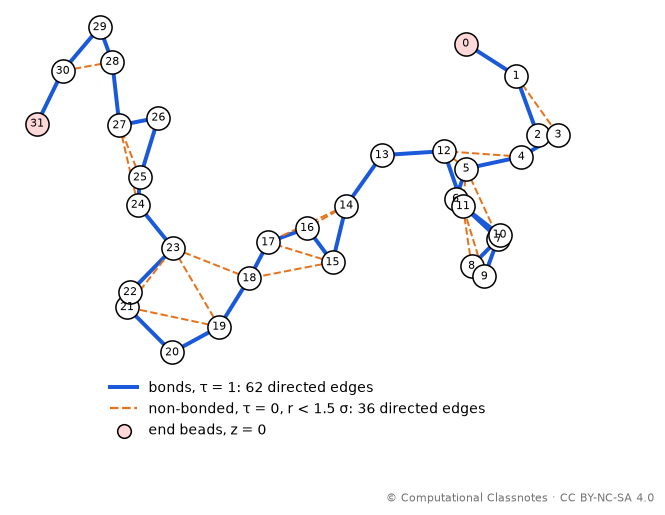

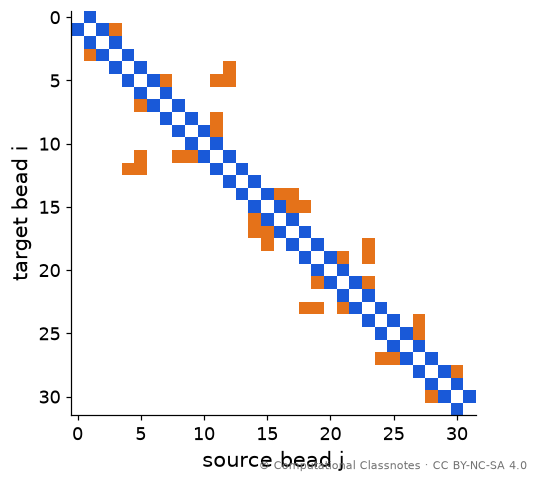

quantity,value
nodes N,32
directed edges |E|,98
bonded (2(N − 1)),62
non-bonded within r_c,36
incoming edges per bead: min / mean / max,1 / 3.06 / 5
shortest non-bonded distance (σ),1.036


In [6]:
# c.5
# the complete graph of frame 0: drawing and adjacency matrix
from polymer_nn.graph import to_data
e0_off = float(E.mean() / 32)                       # the energy offset e₀ used in training (mean energy per bead)
g0 = to_data(P[0], F[0], E[0], cutoff=1.5, energy_offset=e0_off)
src, dst = g0.edge_index.numpy(); et = g0.edge_type.numpy(); N = len(P[0])
xc = P[0] - P[0].mean(0); _, _, Vt = np.linalg.svd(xc); x2 = xc @ Vt[:2].T        # project onto the two main axes
fig, ax = plt.subplots(figsize=(wFull * 1.1, wFull * 0.95))
for j, i, t in zip(src, dst, et):
    if j < i:
        ax.plot(*x2[[j, i]].T, color=blue if t else orange, lw=2.6 if t else 1.3, ls="-" if t else "--", zorder=1)
for i in range(N):
    ax.scatter(*x2[i], s=230, color="white" if g0.z[i] else (1, .85, .85), edgecolor="k", zorder=2)
    ax.text(*x2[i], str(i), ha="center", va="center", fontsize=7.5, zorder=3)
ax.plot([], [], color=blue, lw=2.6, label=f"bonds, τ = 1: {int(et.sum())} directed edges")
ax.plot([], [], color=orange, ls="--", label=f"non-bonded, τ = 0, r < 1.5 σ: {int((et == 0).sum())} directed edges")
ax.scatter([], [], s=80, color=(1, .85, .85), edgecolor="k", label="end beads, z = 0")
ax.set_aspect("equal"); ax.axis("off"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.0), fontsize=9)
savefig(fig, "fig3_graph_frame0"); plt.show()
Adj = np.zeros((N, N)); Adj[dst, src] = np.where(et == 1, 2, 1)
fig, ax = plt.subplots(figsize=(wHalf * 1.6, wHalf * 1.6))
from matplotlib.colors import ListedColormap
ax.imshow(Adj, cmap=ListedColormap(["white", orange, blue]), interpolation="nearest")
ax.set(xlabel="source bead j", ylabel="target bead i"); savefig(fig, "fig4_adjacency"); plt.show()
deg = np.bincount(dst, minlength=N)
table([["quantity", "value"], ["nodes N", N], ["directed edges |E|", len(et)], ["  bonded (2(N − 1))", int(et.sum())],
       ["  non-bonded within r_c", int((et == 0).sum())], ["incoming edges per bead: min / mean / max", f"{deg.min()} / {deg.mean():.2f} / {deg.max()}"],
       ["shortest non-bonded distance (σ)", f"{np.linalg.norm(P[0][src[et == 0]] - P[0][dst[et == 0]], axis=1).min():.3f}"]],
      "Table 6. The graph of frame 0")

*Figure 3. The complete graph of frame 0 of the training data. Beads (numbered along the chain; ends shaded) are projected onto the plane of the chain's two largest extents, so some edges cross in the picture that do not cross in space. Blue: bonds; orange, dashed: non-bonded pairs closer than 1.5 σ. These are the only pairs between which messages pass in one layer.*

*Figure 4. The adjacency matrix of the same graph: entry (i, j) is blue for a bond j → i and orange for a non-bonded edge. The bonds make the two diagonals next to the main diagonal. The orange entries away from them are beads far apart along the chain that touch in space. The matrix is symmetric because every edge is stored both ways.*

## 4. The input tensors

PyTorch Geometric stores the graph as a few tensors in a `Data` object. These tensors are the *complete* input of the network: nothing else about the frame is used. Table 7 lists them for frame 0. For training, B graphs are joined into one `Batch`, a single large graph with B disconnected pieces. Table 8 shows how the indices are shifted, and the vector `batch` that records which chain each bead belongs to, so that energies can be summed per chain.

In [7]:
# c.6
# the tensors that go into the network, for one graph and for a batch of three
from torch_geometric.data import Batch
def show(t, k=6):
    v = t.flatten()[:k].tolist(); return "[" + ", ".join(f"{a:.3f}" if isinstance(a, float) else str(a) for a in v) + ", …]"
table([["tensor", "shape", "type", "meaning", "first values"],
       ["pos", str(tuple(g0.pos.shape)), "float32", "x_i, positions (σ): the geometric input", show(g0.pos)],
       ["z", str(tuple(g0.z.shape)), "int64", "z_i, bead type: 0 = end, 1 = interior", show(g0.z)],
       ["edge_index[0]", str(tuple(g0.edge_index[0].shape)), "int64", "source j of each edge", show(g0.edge_index[0])],
       ["edge_index[1]", str(tuple(g0.edge_index[1].shape)), "int64", "target i of each edge", show(g0.edge_index[1])],
       ["edge_type", str(tuple(g0.edge_type.shape)), "int64", "τ_ij: 1 = bond, 0 = non-bonded", show(g0.edge_type)],
       ["force (target)", str(tuple(g0.force.shape)), "float32", "OpenMM forces (ε/σ), used only in the loss", show(g0.force)],
       ["energy (target)", str(tuple(g0.energy.shape)), "float32", f"E − N e₀ (ε), e₀ = {e0_off:.3f}; used only in the loss", show(g0.energy)]],
      "Table 7. The network input for frame 0 (a torch_geometric Data object)")
gs = [to_data(P[k], F[k], E[k]) for k in (0, 1, 2)]; bt = Batch.from_data_list(gs)
table([["tensor of the batch", "shape", "what changed"], ["pos", str(tuple(bt.pos.shape)), "the 3 × 32 beads stacked"],
       ["edge_index", str(tuple(bt.edge_index.shape)), f"indices of graph g shifted by 32 g: max index {int(bt.edge_index.max())}"],
       ["batch", str(tuple(bt.batch.shape)), "graph of each bead: " + show(bt.batch[28:36], 8).replace("…", "") + " (beads 28–35)"],
       ["ptr", str(tuple(bt.ptr.shape)), "where each graph starts: " + str(bt.ptr.tolist())],
       ["energy", str(tuple(bt.energy.shape)), "one target energy per graph"]], "Table 8. Three graphs as one batch")

tensor,shape,type,meaning,first values
pos,"(32, 3)",float32,"x_i, positions (σ): the geometric input","[2.947, -8.379, -1.387, 3.630, -8.649, -0.760, …]"
z,"(32,)",int64,"z_i, bead type: 0 = end, 1 = interior","[0, 1, 1, 1, 1, 1, …]"
edge_index[0],"(98,)",int64,source j of each edge,"[0, 1, 2, 3, 4, 5, …]"
edge_index[1],"(98,)",int64,target i of each edge,"[1, 2, 3, 4, 5, 6, …]"
edge_type,"(98,)",int64,"τ_ij: 1 = bond, 0 = non-bonded","[1, 1, 1, 1, 1, 1, …]"
force (target),"(32, 3)",float32,"OpenMM forces (ε/σ), used only in the loss","[2.923, -1.155, 2.681, 32.879, 0.120, -6.565, …]"
energy (target),"(1,)",float32,"E − N e₀ (ε), e₀ = 20.117; used only in the loss","[-1.668, …]"


tensor of the batch,shape,what changed
pos,"(96, 3)",the 3 × 32 beads stacked
edge_index,"(2, 320)",indices of graph g shifted by 32 g: max index 95
batch,"(96,)","graph of each bead: [0, 0, 0, 0, 1, 1, 1, 1, ] (beads 28–35)"
ptr,"(4,)","where each graph starts: [0, 32, 64, 96]"
energy,"(3,)",one target energy per graph


## 5. Inside the network: the full computational graph

Figure 5 is the complete computation of `InvariantGNN` (notebook 00, section 6.3; `polymer_nn.models`, Eqs. (M1)–(M10)). It shows the symbol of each quantity and the shape of each tensor for a graph with N nodes and |E| edges, with H = 64 channels and K = 32 radial functions. Data flows left to right in the forward pass. The dashed red arrow is the backward pass of automatic differentiation, which turns the energy into the forces. Cell c.8 runs the network on frame 0 with a `trace`, which records every intermediate tensor, and lists their shapes and sizes (Table 9) and the number of weights in each block (Table 10).

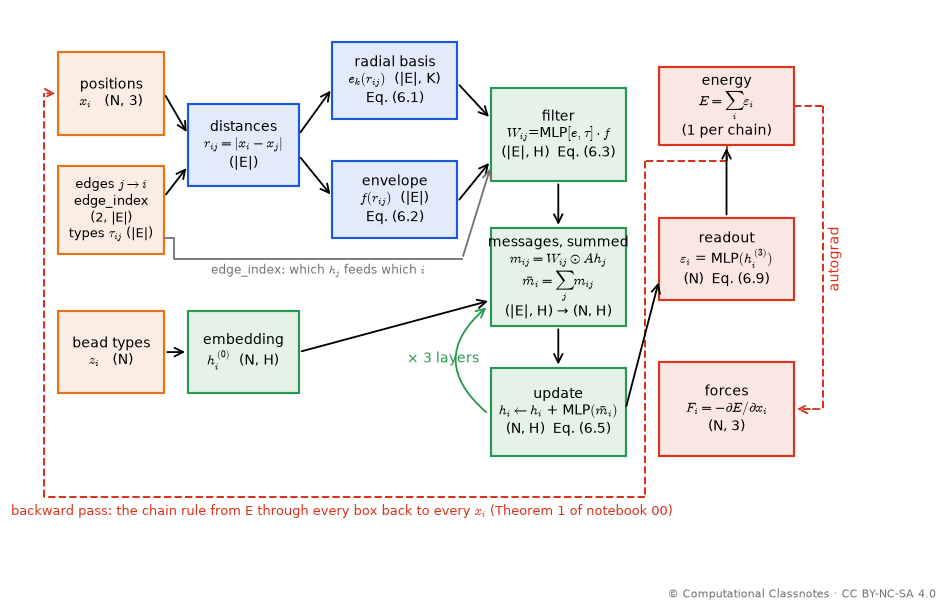

In [8]:
# c.7
# Figure 5: the computational graph of InvariantGNN, with symbols and tensor shapes
fig, ax = plt.subplots(figsize=(wFull * 1.55, wFull * 1.0)); ax.axis("off"); ax.set_xlim(0, 16.8); ax.set_ylim(0, 10)
def box(x, y, w, h, txt, c, fs=9):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=(*c, 0.12), ec=c, lw=1.4)); ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs)
def arrow(a, b, c="k", ls="-"):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", lw=1.2, color=c, ls=ls))
def path(pts, c=red):   # a dashed polyline ending in an arrow
    for p0, p1 in zip(pts[:-2], pts[1:-1]): ax.plot(*zip(p0, p1), color=c, ls="--", lw=1.3)
    arrow(pts[-2], pts[-1], c, "--")
box(0.6, 7.6, 2.2, 1.6, "positions\n$x_i$   (N, 3)", orange); box(0.6, 5.3, 2.2, 1.7, "edges $j\\to i$\nedge_index\n(2, |E|)\ntypes $\\tau_{ij}$ (|E|)", orange, 8.5)
box(0.6, 2.6, 2.2, 1.6, "bead types\n$z_i$   (N)", orange)
box(3.3, 6.6, 2.3, 1.6, "distances\n$r_{ij}=|x_i-x_j|$\n(|E|)", blue)
box(6.3, 7.9, 2.6, 1.5, "radial basis\n$e_k(r_{ij})$  (|E|, K)\nEq. (6.1)", blue); box(6.3, 5.6, 2.6, 1.5, "envelope\n$f(r_{ij})$  (|E|)\nEq. (6.2)", blue)
box(3.3, 2.6, 2.3, 1.6, "embedding\n$h_i^{(0)}$  (N, H)", green)
box(9.6, 6.7, 2.8, 1.8, "filter\n$W_{ij}$=MLP$[e,\\tau]\\cdot f$\n(|E|, H)  Eq. (6.3)", green)
box(9.6, 3.9, 2.8, 1.9, "messages, summed\n$m_{ij}=W_{ij}\\odot A h_j$\n$\\bar m_i=\\sum_j m_{ij}$\n(|E|, H) → (N, H)", green)
box(9.6, 1.4, 2.8, 1.7, "update\n$h_i \\leftarrow h_i$ + MLP$(\\bar m_i)$\n(N, H)  Eq. (6.5)", green)
box(13.1, 4.4, 2.8, 1.6, "readout\n$\\varepsilon_i$ = MLP$(h_i^{(3)})$\n(N)  Eq. (6.9)", red)
box(13.1, 7.4, 2.8, 1.5, "energy\n$E=\\sum_i \\varepsilon_i$\n(1 per chain)", red)
box(13.1, 1.4, 2.8, 1.8, "forces\n$F_i=-\\partial E/\\partial x_i$\n(N, 3)", red)
arrow((2.8, 8.4), (3.3, 7.6)); arrow((2.8, 6.4), (3.3, 7.0)); arrow((5.6, 7.6), (6.3, 8.5)); arrow((5.6, 7.2), (6.3, 6.4))
arrow((2.8, 3.4), (3.3, 3.4)); arrow((8.9, 8.6), (9.6, 7.9)); arrow((8.9, 6.3), (9.6, 7.1))
ax.plot([2.8, 3.0, 3.0, 9.0], [5.6, 5.6, 5.2, 5.2], color=grey, lw=1.2); arrow((9.0, 5.2), (9.6, 7.0), grey)
ax.text(6.0, 4.9, "edge_index: which $h_j$ feeds which $i$", fontsize=8, color=grey, ha="center")
arrow((11.0, 6.7), (11.0, 5.8)); arrow((5.6, 3.4), (9.6, 4.4)); arrow((11.0, 3.9), (11.0, 3.1))
ax.annotate("", xy=(9.55, 4.3), xytext=(9.55, 2.2), arrowprops=dict(arrowstyle="->", lw=1.2, color=green, connectionstyle="arc3,rad=-0.6"))
ax.text(8.6, 3.2, "× 3 layers", color=green, fontsize=9, ha="center")
arrow((12.4, 2.3), (13.1, 4.8)); arrow((14.5, 6.0), (14.5, 7.4))
path([(15.9, 8.15), (16.5, 8.15), (16.5, 2.3), (15.9, 2.3)])                          # E -> F by autograd
ax.text(16.6, 5.2, "autograd", rotation=90, color=red, fontsize=9, va="center")
path([(14.5, 7.4), (14.5, 7.1), (12.8, 7.1), (12.8, 0.6), (0.3, 0.6), (0.3, 8.4), (0.6, 8.4)])   # backward pass to x
ax.text(6.5, 0.25, "backward pass: the chain rule from E through every box back to every $x_i$ (Theorem 1 of notebook 00)", color=red, fontsize=8.5, ha="center")
savefig(fig, "fig5_computational_graph"); plt.show()

*Figure 5. The computational graph of `InvariantGNN`. Orange: the input tensors of Table 7. Blue: geometry, computed per edge. Green: the three message-passing layers, which share one structure but have separate weights. Red: the outputs. Every arrow is a differentiable operation, so PyTorch can run the chain rule backwards from E to the positions (dashed), which gives all N forces at the cost of about one more forward pass.*

In [9]:
# c.8
# run the trained network on frame 0 and record every intermediate tensor
from polymer_nn.models import load_model
inv, ck_inv = load_model(ROOT / "models/invariant.pt"); egnn, ck_eg = load_model(ROOT / "models/egnn.pt")
tr = {}; e_pred, f_pred = inv(to_data(P[0]), trace=tr)
sym = {"r": "r_ij, distance on every edge", "rbf": "e_k(r_ij), radial basis, Eq. (6.1)", "env": "f(r_ij), envelope, Eq. (6.2)",
       "h0": "h_i⁽⁰⁾, embedding of the bead type", "h1": "h_i⁽¹⁾ after layer 1", "h2": "h_i⁽²⁾ after layer 2",
       "h3": "h_i⁽³⁾ after layer 3", "e_i": "ε_i, energy of each bead, Eq. (6.9)"}
table([["tensor", "symbol and meaning", "shape", "numbers"]] + [[k, sym[k], str(tuple(v.shape)), v.numel()] for k, v in tr.items()] +
      [["E", "total energy (+ N e₀ gives OpenMM's scale)", "(1,)", 1], ["F", "forces −∂E/∂x by autograd", str(tuple(f_pred.shape)), f_pred.numel()]],
      "Table 9. Every intermediate tensor of InvariantGNN on frame 0")
def count(m): return sum(p.numel() for p in m.parameters())
rows = [["block", "InvariantGNN weights", "block", "EquivariantGNN weights"]]
ib = [("embedding h⁽⁰⁾", inv.embed)] + [(f"layer {l + 1} (filter, A, update)", c) for l, c in enumerate(inv.convs)] + [("readout", inv.readout)]
eb = [("embedding h⁽⁰⁾", egnn.embed)] + [(f"layer {l + 1} (φ_e, φ_x, φ_h)", c) for l, c in enumerate(egnn.layers)] + [("readout", egnn.readout)]
for (a, ma), (b, mb) in zip(ib, eb): rows.append([a, count(ma), b, count(mb)])
rows.append(["total", count(inv), "total", count(egnn)])
table(rows, "Table 10. Where the weights are")

tensor,symbol and meaning,shape,numbers
r,"r_ij, distance on every edge","(98,)",98
rbf,"e_k(r_ij), radial basis, Eq. (6.1)","(98, 32)",3 136
env,"f(r_ij), envelope, Eq. (6.2)","(98,)",98
h0,"h_i⁽⁰⁾, embedding of the bead type","(32, 64)",2 048
h1,h_i⁽¹⁾ after layer 1,"(32, 64)",2 048
h2,h_i⁽²⁾ after layer 2,"(32, 64)",2 048
h3,h_i⁽³⁾ after layer 3,"(32, 64)",2 048
e_i,"ε_i, energy of each bead, Eq. (6.9)","(32,)",32
E,total energy (+ N e₀ gives OpenMM's scale),"(1,)",1
F,forces −∂E/∂x by autograd,"(32, 3)",96


block,InvariantGNN weights,block,EquivariantGNN weights
embedding h⁽⁰⁾,128,embedding h⁽⁰⁾,128
"layer 1 (filter, A, update)",18 816,"layer 1 (φ_e, φ_x, φ_h)",31 233
"layer 2 (filter, A, update)",18 816,"layer 2 (φ_e, φ_x, φ_h)",31 233
"layer 3 (filter, A, update)",18 816,"layer 3 (φ_e, φ_x, φ_h)",31 233
readout,4 225,readout,4 225
total,60 801,total,98 052


## 6. Symbolics on the graph

To see the network as mathematics rather than code, take the smallest chain with every ingredient: three beads 0–1–2, two bonds, two end beads (z = 0) and one interior bead (z = 1), and no non-bonded edge. Shrink the network to one channel (H = 1), K = 2 radial functions and one layer, with linear filter, update and readout, so that every step can be written by hand. The embedding gives h₀ = h₂ = α (ends) and h₁ = β (interior). Then for every directed edge j → i

$$
W_{ij} = w_1 e_1(r_{ij}) + w_2 e_2(r_{ij}) + c , \qquad e_k(r) = e^{-\gamma (r - \mu_k)^2} \tag{2}
$$

$$
\bar m_i = \sum_{j \in \mathcal N(i)} W_{ij}\, a\, h_j , \qquad h_i' = h_i + u\, \bar m_i , \qquad \varepsilon_i = q\, h_i' + p , \qquad E = \varepsilon_0 + \varepsilon_1 + \varepsilon_2 \tag{3}
$$

with weights w₁, w₂, c, a, u, q, p. Cell c.9 builds E with SymPy, both as a function of the nine coordinates of the three beads and as a function of the two bond lengths. It differentiates E and compares the force on the end bead 0 with Eq. (4), symbolically and numerically. The result has a clear form. E depends on the coordinates only through r₀₁ and r₁₂, so the force on bead 0 is a scalar times the unit vector along its bond,

$$
F_0 = -\frac{\partial E}{\partial r_{01}} \, \hat u_{01} , \qquad \hat u_{01} = \frac{x_0 - x_1}{r_{01}} \tag{4}
$$

This is a general fact about networks that see only distances:

**Theorem 1 (forces of an invariant graph network are sums of pair forces).** Let E depend on the positions only through the distances $r_e = |x_{i(e)} - x_{j(e)}|$ of the edges e of the graph. Then

$$
F_i = -\sum_{e \ni i} \frac{\partial E}{\partial r_e} \, \hat u_{e,i} , \qquad \hat u_{e,i} = \frac{x_i - x_{\text{other}(e)}}{r_e} \tag{5}
$$

so every edge contributes equal and opposite forces to its two beads (Newton's third law, edge by edge), and

$$
\sum_i F_i = 0 . \tag{6}
$$

*Proof.* The chain rule gives ∂E/∂x_i = Σ_e (∂E/∂r_e)(∂r_e/∂x_i). For an edge between i and j, ∂r_e/∂x_i = (x_i − x_j)/r_e and ∂r_e/∂x_j = −(x_i − x_j)/r_e, and ∂r_e/∂x_k = 0 for every other bead. So edge e contributes −(∂E/∂r_e) û to bead i and the opposite vector to bead j. Summing over all beads, the contributions cancel in pairs. ∎

The coefficients ∂E/∂r_e are not fixed pair potentials: through the messages, each one depends on the whole neighbourhood. This is what makes the network more expressive than a pair potential, while its forces keep the pair structure. Cell c.10 checks Theorem 1 on the trained `InvariantGNN` and frame 0. It computes the 98 numbers ∂E/∂r_e (one per directed edge) with autograd, assembles the forces from Eq. (5), and compares them with the forces of the network.

In [10]:
# c.9
# SymPy: the tiny network of Eqs. (2)-(3) on the 3-bead chain, its energy, and the force on bead 0
import sympy as sp
X = sp.Matrix(3, 3, lambda i, k: sp.Symbol(f"x_{i}{'xyz'[k]}", real=True))     # coordinates of beads 0, 1, 2
w1, w2, c, a, u, q, p, al, be, gam, mu1, mu2 = sp.symbols("w_1 w_2 c a u q p alpha beta gamma mu_1 mu_2", real=True)
dist = lambda i, j: sp.sqrt(sum((X[i, k] - X[j, k]) ** 2 for k in range(3)))
e_ = lambda r, mu: sp.exp(-gam * (r - mu) ** 2)
Wf = lambda r: w1 * e_(r, mu1) + w2 * e_(r, mu2) + c                              # Eq. (2)
h = [al, be, al]                                                                # embedding: ends alpha, interior beta
edges = [(0, 1), (1, 0), (1, 2), (2, 1)]                                        # (j, i): message j -> i
mbar = [sum(Wf(dist(j, i)) * a * h[j] for j, i in edges if i == ii) for ii in range(3)]
eps = [q * (h[ii] + u * mbar[ii]) + p for ii in range(3)]                       # Eq. (3)
Esym = sum(eps)                                                               # E as a function of the 9 coordinates
# the same energy written with the two bond lengths as symbols: E depends on x only through r01, r12
r01, r12 = sp.symbols("r_01 r_12", positive=True)
rsym = {(0, 1): r01, (1, 0): r01, (1, 2): r12, (2, 1): r12}
mbar_r = [sum(Wf(rsym[(j, i)]) * a * h[j] for j, i in edges if i == ii) for ii in range(3)]
E_r = sp.collect(sp.expand(sum(q * (h[ii] + u * mbar_r[ii]) + p for ii in range(3))), [q])
print("E(r01, r12) =", E_r)
print("∂E/∂r01 =", sp.factor(sp.diff(E_r, r01)))
F0 = [-sp.diff(Esym, X[0, k]) for k in range(3)]                                # force on bead 0 from the coordinates
F0_eq4 = [-sp.diff(E_r, r01).subs(r01, dist(0, 1)) * (X[0, k] - X[1, k]) / dist(0, 1) for k in range(3)]   # Eq. (4)
# numbers: the same tiny network in PyTorch, with random weights, compared with SymPy at a random configuration
vals = {w1: 0.7, w2: -1.3, c: 0.2, a: 0.9, u: 1.1, q: -0.6, p: 0.3, al: 0.5, be: -0.8, gam: 8.0, mu1: 0.9, mu2: 1.1}
xnum = np.array([[0, 0, 0], [0.97, 0.05, 0], [1.4, 0.9, 0.1]])
subs = {**vals, **{X[i, k]: xnum[i, k] for i in range(3) for k in range(3)}}
E_sym_num = float(Esym.subs(subs)); F0_sym = np.array([float(f.subs(subs)) for f in F0])
F0_eq4_num = np.array([float(f.subs(subs)) for f in F0_eq4])
xt = torch.tensor(xnum, requires_grad=True)
def tiny(x):
    r_ = lambda i, j: (x[i] - x[j]).norm()
    W_ = lambda r: vals[w1] * torch.exp(-vals[gam] * (r - vals[mu1]) ** 2) + vals[w2] * torch.exp(-vals[gam] * (r - vals[mu2]) ** 2) + vals[c]
    hh = [vals[al], vals[be], vals[al]]
    mb = [sum(W_(r_(j, i)) * vals[a] * hh[j] for j, i in edges if i == ii) for ii in range(3)]
    return sum(vals[q] * (hh[ii] + vals[u] * mb[ii]) + vals[p] for ii in range(3))
Et = tiny(xt); (gt,) = torch.autograd.grad(Et, xt)
table([["quantity", "SymPy", "PyTorch autograd"], ["E", nform(E_sym_num, 10), nform(float(Et), 10)],
       ["F_0 = −∂E/∂x_0", "(" + ", ".join(f"{v:.8f}" for v in F0_sym) + ")", "(" + ", ".join(f"{v:.8f}" for v in -gt[0].numpy()) + ")"],
       ["F_0 from Eq. (4), −(∂E/∂r01) û01", "(" + ", ".join(f"{v:.8f}" for v in F0_eq4_num) + ")", ""]],
      "Table 11. The tiny network symbolically and numerically")

E(r01, r12) = 3*p + q*(2*a*alpha*c*u + a*alpha*u*w_1*exp(-gamma*mu_1**2)*exp(-gamma*r_12**2)*exp(2*gamma*mu_1*r_12) + a*alpha*u*w_1*exp(-gamma*mu_1**2)*exp(-gamma*r_01**2)*exp(2*gamma*mu_1*r_01) + a*alpha*u*w_2*exp(-gamma*mu_2**2)*exp(-gamma*r_12**2)*exp(2*gamma*mu_2*r_12) + a*alpha*u*w_2*exp(-gamma*mu_2**2)*exp(-gamma*r_01**2)*exp(2*gamma*mu_2*r_01) + 2*a*beta*c*u + a*beta*u*w_1*exp(-gamma*mu_1**2)*exp(-gamma*r_12**2)*exp(2*gamma*mu_1*r_12) + a*beta*u*w_1*exp(-gamma*mu_1**2)*exp(-gamma*r_01**2)*exp(2*gamma*mu_1*r_01) + a*beta*u*w_2*exp(-gamma*mu_2**2)*exp(-gamma*r_12**2)*exp(2*gamma*mu_2*r_12) + a*beta*u*w_2*exp(-gamma*mu_2**2)*exp(-gamma*r_01**2)*exp(2*gamma*mu_2*r_01) + 2*alpha + beta)
∂E/∂r01 = 2*a*gamma*q*u*(alpha + beta)*(mu_1*w_1*exp(gamma*mu_2**2)*exp(2*gamma*mu_1*r_01) + mu_2*w_2*exp(gamma*mu_1**2)*exp(2*gamma*mu_2*r_01) - r_01*w_1*exp(gamma*mu_2**2)*exp(2*gamma*mu_1*r_01) - r_01*w_2*exp(gamma*mu_1**2)*exp(2*gamma*mu_2*r_01))*exp(-gamma*mu_1**2)*exp(-gamma*mu_2**2)*exp(-gamma*

quantity,SymPy,PyTorch autograd
E,0.6925311649,0.6925311649
F_0 = −∂E/∂x_0,"(-0.55373630, -0.02854311, 0.00000000)","(-0.55373630, -0.02854311, -0.00000000)"
"F_0 from Eq. (4), −(∂E/∂r01) û01","(-0.55373630, -0.02854311, 0.00000000)",


max |F from Eq. (5) − F from the network| = 7.63e-06 ε/σ;  |Σ_i F_i| = 1.80e-05;  number of edge coefficients ∂E/∂r_e: 98


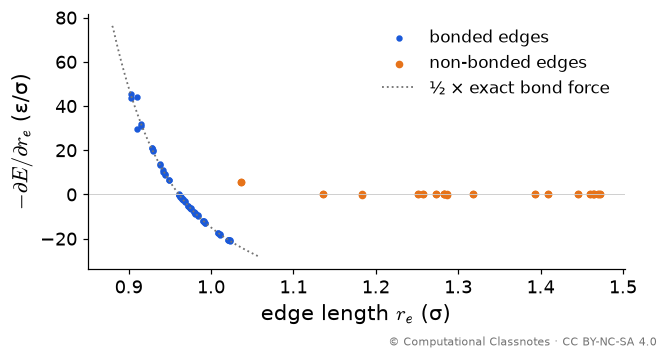

In [11]:
# c.10
# Theorem 1 on the trained InvariantGNN: forces assembled from the edge derivatives dE/dr_e, Eq. (5)
g = to_data(P[0]); pos = g.pos.clone().requires_grad_(True); s_, d_ = g.edge_index
r_e = (pos[d_] - pos[s_]).norm(dim=-1)                                   # distances of every edge
# rebuild the network's energy from these distances by passing r through the same layers
from polymer_nn.models import edge_envelope
rbf = inv.rbf(r_e); env = edge_envelope(r_e, g.edge_type, inv.cutoff); hcur = inv.embed(g.z)
for conv in inv.convs: hcur = conv(hcur, g.edge_index, rbf, g.edge_type, env)
Etot = inv.readout(hcur).sum()
dEdr, dEdx = torch.autograd.grad(Etot, [r_e, pos], retain_graph=True)   # dE/dr_e (|E|,) and dE/dx (N, 3)
uvec = (pos[d_] - pos[s_]).detach() / r_e.detach()[:, None]              # unit vector from source to target
F_pairs = torch.zeros(N, 3, dtype=torch.float32)
F_pairs.index_add_(0, d_, -dEdr[:, None] * uvec); F_pairs.index_add_(0, s_, dEdr[:, None] * uvec)   # Eq. (5)
F_net = inv(to_data(P[0]))[1].detach()
print(f"max |F from Eq. (5) − F from the network| = {float((F_pairs + dEdx * 0 - F_net).abs().max()):.2e} ε/σ;  "
      f"|Σ_i F_i| = {float(F_net.sum(0).norm()):.2e};  number of edge coefficients ∂E/∂r_e: {len(dEdr)}")
fig, ax = plt.subplots(figsize=(wFull, wHalf * 1.1))
bond = g.edge_type.numpy() == 1; rr_ = r_e.detach().numpy(); gg = -dEdr.numpy()
ax.scatter(rr_[bond], gg[bond], s=10, color=blue, label="bonded edges"); ax.scatter(rr_[~bond], gg[~bond], s=16, color=orange, label="non-bonded edges")
rb_ = np.linspace(0.88, 1.06, 200)
Fb = -np.gradient(-0.5 * 30 * 2.25 * np.log(1 - (rb_ / 1.5)**2) + 4 * (rb_**-12 - rb_**-6), rb_)
ax.plot(rb_, 0.5 * Fb, color=grey, lw=1.2, ls=":", label="½ × exact bond force")
ax.axhline(0, color="0.8", lw=0.6); ax.set(xlabel="edge length $r_e$ (σ)", ylabel=r"$-\partial E/\partial r_e$ (ε/σ)"); ax.legend()
fig.tight_layout(); savefig(fig, "fig6_edge_forces"); plt.show()

*Figure 6. The edge coefficients −∂E/∂r_e of Eq. (5) for frame 0, the strength of the pair force carried by each edge, against the edge length. Each bond appears as two directed edges, and the network is free to split the bond force between them, so the dotted line shows half the exact FENE + WCA bond force, the value for an equal split. The learned values cross zero near 0.96 σ, as the exact force does: they are attractive when a bond is stretched and repulsive when it is compressed. Non-bonded edges inside the WCA range (r < 1.12 σ) push apart: the one at 1.04 σ carries about 5 ε/σ, half the exact WCA force there. Those beyond the WCA range carry almost nothing, as they should. The scatter around the curves is the many-body part: the same distance can carry a different force in a different neighbourhood.*

## 7. What comes out

The trained network (notebook 03) is now applied to a frame from the *test* file, a 64-bead chain. It was never trained on this chain length. The outputs are the total energy, the energy ε_i of every bead, and the force on every bead. They are compared with the exact values from OpenMM in Table 12 and Figures 7–8.

bead i,type z_i,ε_i (ε),F_i from OpenMM (ε/σ),F_i from the network (ε/σ)
0,0,20.791,"(-22.15, +8.26, -15.93)","(-22.32, +8.27, -15.92)"
1,1,19.801,"(+28.38, -2.42, +0.07)","(+28.48, -2.06, -0.60)"
2,1,19.953,"(+15.28, -3.89, +14.49)","(+15.43, -3.82, +14.54)"
31,1,20.009,"(-33.19, -27.48, -32.94)","(-33.28, -27.63, -33.09)"
63,0,21.283,"(-28.81, +54.96, -5.82)","(-28.81, +54.96, -5.82)"
all 64,,E = 1288.69,E = 1310.06,RMS force error 0.520


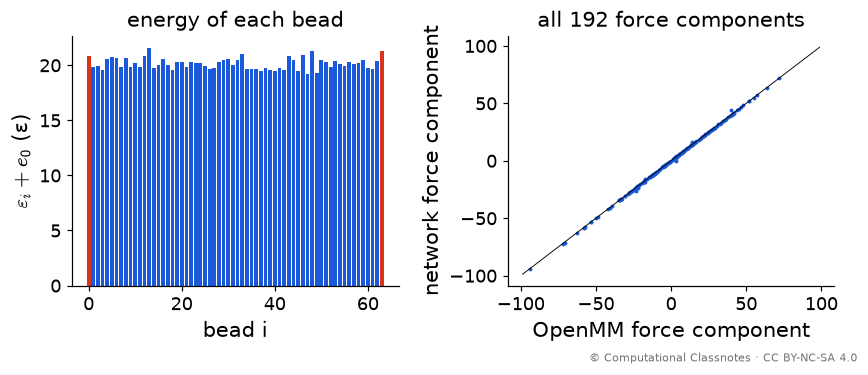

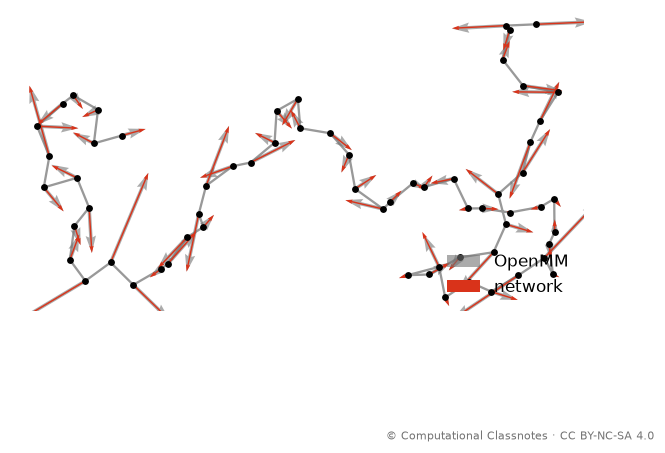

In [12]:
# c.11
# outputs of the trained network on a 64-bead test frame, against OpenMM
d64 = np.load(DATA / "kg_N64.npz"); x64, F64, E64 = d64["positions"][123], d64["forces"][123], d64["energy"][123]
tr = {}; e64, f64 = inv(to_data(x64), trace=tr); f64 = f64.detach().numpy(); eps_i = tr["e_i"].detach().numpy()
E_pred = float(e64.detach()) + ck_inv["energy_offset"] * 64
rows = [["bead i", "type z_i", "ε_i (ε)", "F_i from OpenMM (ε/σ)", "F_i from the network (ε/σ)"]]
for i in (0, 1, 2, 31, 63):
    rows.append([i, int(i in (0, 63)) * 0 + (0 if i in (0, 63) else 1), f"{eps_i[i] + ck_inv['energy_offset']:.3f}",
                 "(" + ", ".join(f"{v:+.2f}" for v in F64[i]) + ")", "(" + ", ".join(f"{v:+.2f}" for v in f64[i]) + ")"])
rows += [["all 64", "", f"E = {E_pred:.2f}", f"E = {E64:.2f}", f"RMS force error {np.sqrt(((f64 - F64)**2).mean()):.3f}"]]
table(rows, "Table 12. Network output for frame 123 of the 64-bead test chain")
fig, ax = plt.subplots(1, 2, figsize=(wFull * 1.3, wHalf * 1.15))
ax[0].bar(range(64), eps_i + ck_inv["energy_offset"], color=[red if i in (0, 63) else blue for i in range(64)])
ax[0].set(xlabel="bead i", ylabel=r"$\varepsilon_i + e_0$ (ε)", title="energy of each bead")
ax[1].plot(F64.ravel(), f64.ravel(), ".", ms=3, color=blue); lim = np.abs(F64).max() * 1.05
ax[1].plot([-lim, lim], [-lim, lim], "k", lw=0.6); ax[1].set(xlabel="OpenMM force component", ylabel="network force component", title="all 192 force components")
fig.tight_layout(); savefig(fig, "fig7_outputs"); plt.show()
xc = x64 - x64.mean(0); _, _, Vt = np.linalg.svd(xc); x2 = xc @ Vt[:2].T; F2, f2 = F64 @ Vt[:2].T, f64 @ Vt[:2].T
fig, ax = plt.subplots(figsize=(wFull * 1.1, wFull * 0.85))
ax.plot(*x2.T, color="0.6", lw=1.5, zorder=1); ax.scatter(*x2.T, s=12, color="k", zorder=2)
ax.quiver(*x2.T, *F2.T, color=grey, alpha=0.6, scale=600, width=0.006, label="OpenMM")
ax.quiver(*x2.T, *f2.T, color=red, scale=600, width=0.0025, label="network")
ax.set_aspect("equal"); ax.axis("off"); ax.legend(loc="lower right")
savefig(fig, "fig8_force_arrows"); plt.show()

*Figure 7. Left: the energy of each bead, ε_i + e₀, for the 64-bead test frame. The end beads (red) have one bond fewer, and the network gives them their own share of the energy. The interior beads differ by their bond stretches and contacts. Only the sum is a physical quantity; the split into beads is the network's own bookkeeping. Right: every force component predicted by the network against OpenMM.*

The total energy in Table 12 is lower than OpenMM's by about 0.33 ε per bead, a constant. Training data with a single chain length (N = 32, two end beads) fix the total energy but not how a constant is split between end beads and interior beads. On a chain with a different ratio of ends to interior beads, that split shows up as a constant shift per bead. A constant changes no force and no dynamics, so the forces agree bead by bead; up to the constant, the energy error is below 10⁻³ ε per bead (notebook 03). Training on two chain lengths would fix the constant too.

*Figure 8. The force on every bead of the test frame, projected onto the plane of the chain: OpenMM (broad grey arrows) and the network (thin red arrows). They agree bead by bead, on a chain twice as long as any used in training.*

## 8. Summary

*Table 13. Input and output of the networks.*

| | quantity | symbol | shape | unit | source |
|---|---|---|---|---|---|
| input | bead positions | x_i | N × 3 | σ | OpenMM frame (`positions`) |
| input | bead types | z_i | N | – | 0 for the two ends, 1 inside |
| input | edges and their types | j → i, τ_ij | 2 × \|E\|, \|E\| | – | built from x by Eq. (1) |
| inside | distances, radial basis, envelope | r_ij, e(r_ij), f(r_ij) | \|E\|, \|E\| × 32, \|E\| | σ, –, – | Eqs. (6.1)–(6.2) of notebook 00 |
| inside | features after each layer | $h_i^{(t)}$ | N × 64 | – | Eqs. (6.3)–(6.5) |
| output | energy per bead | ε_i | N | ε | readout, Eq. (6.9) |
| output | total energy | E = Σ ε_i (+ N e₀) | 1 | ε | compared with `energy` |
| output | forces | F_i = −∂E/∂x_i | N × 3 | ε/σ | autograd; compared with `forces` |

## References

- [eastman2017] P. Eastman et al., OpenMM 7: Rapid development of high performance algorithms for molecular dynamics, PLOS Comput. Biol. 13 (2017) e1005659. doi:10.1371/journal.pcbi.1005659
- [kremer1990] K. Kremer, G. S. Grest, J. Chem. Phys. 92 (1990) 5057–5086. doi:10.1063/1.458541
- [fey2019] M. Fey, J. E. Lenssen, Fast graph representation learning with PyTorch Geometric, arXiv:1903.02428 (2019).
- [schutt2017] K. T. Schütt et al., SchNet, NeurIPS 30 (2017).
- Notebook 00 of this repository, *Graph Networks for Polymers: The Theory*. The complete bibliography: `docs/REFERENCES.md`.

<p align='center' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>